SkinAI
     Model training
     

Imports libraries

In [2]:
%pip install pandas


  Using cached pandas-3.0.6-cp311-cp311-win_amd64.whl.metadata (19 kB)
  Using cached numpy-2.4.6-cp311-cp311-win_amd64.whl.metadata (6.6 kB)
Using cached pandas-3.0.6-cp311-cp311-win_amd64.whl (9.9 MB)
Using cached numpy-2.4.6-cp311-cp311-win_amd64.whl (12.6 MB)
   ---------------------------------------- 0.0/348.0 kB ? eta -:--:--
   - -------------------------------------- 10.2/348.0 kB ? eta -:--:--
   - -------------------------------------- 10.2/348.0 kB ? eta -:--:--
   --- ----------------------------------- 30.7/348.0 kB 259.2 kB/s eta 0:00:02
   ------ -------------------------------- 61.4/348.0 kB 326.1 kB/s eta 0:00:01
   ---------- ---------------------------- 92.2/348.0 kB 401.6 kB/s eta 0:00:01
   ------------ ------------------------- 112.6/348.0 kB 435.7 kB/s eta 0:00:01
   --------------------- ---------------- 194.6/348.0 kB 620.6 kB/s eta 0:00:01
   ------------------------- ------------ 235.5/348.0 kB 654.9 kB/s eta 0:00:01
   ------------------------------ -------


[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [21]:
%pip install matplotlib
%pip install seaborn
%pip install tensorflow


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


  Using cached tensorflow-2.21.0-cp311-cp311-win_amd64.whl.metadata (4.5 kB)
  Using cached absl_py-2.5.0-py3-none-any.whl.metadata (3.3 kB)
  Using cached astunparse-1.6.3-py2.py3-none-any.whl.metadata (4.4 kB)
  Using cached flatbuffers-25.12.19-py2.py3-none-any.whl.metadata (1.0 kB)
  Using cached gast-0.7.0-py3-none-any.whl.metadata (1.5 kB)
  Using cached google_pasta-0.2.0-py3-none-any.whl.metadata (814 bytes)
  Using cached libclang-18.1.1-py2.py3-none-win_amd64.whl.metadata (5.3 kB)
  Using cached opt_einsum-3.4.0-py3-none-any.whl.metadata (6.3 kB)
  Using cached protobuf-7.36.2-cp310-abi3-win_amd64.whl.metadata (595 bytes)
  Using cached requests-2.34.2-py3-none-any.whl.metadata (4.8 kB)
  Using cached termcolor-3.3.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached wrapt-2.5.0-cp311-cp311-win_amd64.whl.metadata (7.7 kB)
  Using cached grpcio-1.84.0-cp311-cp311-win_amd64.whl.metadata (3.9 kB)
  Using cached keras-3.15.1-py3-none-any.whl.metadata (6.4 kB)
  Using cached h5py-3


[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [6]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Imports successful")

Imports successful


Load Dataset

In [7]:
metadata_path = "../data/raw/HAM10000_metadata.csv"
df = pd.read_csv(metadata_path)
print("Dataset shape:", df.shape)
df.head()

Dataset shape: (10015, 7)


,lesion_id,image_id,dx,dx_type,age,sex,localization
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear


In [8]:
#check class
print(df["dx"].value_counts())

dx
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64


In [9]:
#check class distribution
print(df["dx"].value_counts(normalize=True) * 100)

dx
nv       66.949576
mel      11.113330
bkl      10.973540
bcc       5.132302
akiec     3.265102
vasc      1.417873
df        1.148278
Name: proportion, dtype: float64


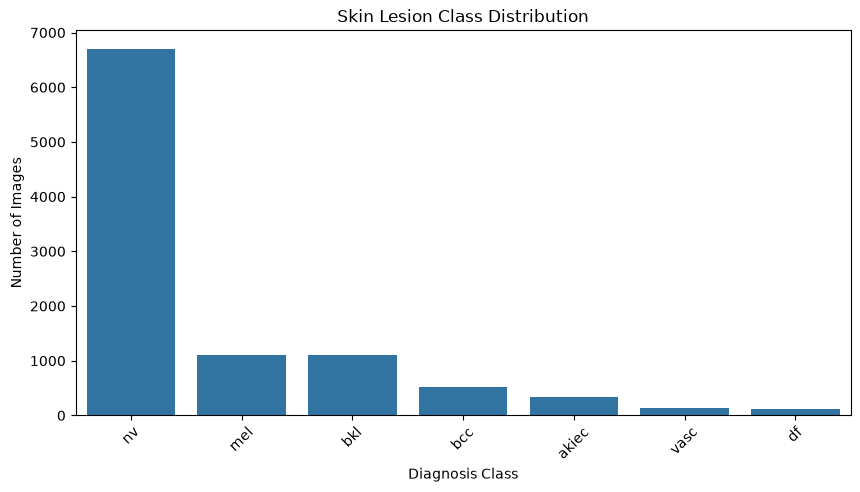

In [10]:
#visualization
plt.figure(figsize=(10, 5))

sns.countplot(data=df, x="dx", order=df["dx"].value_counts().index)

plt.title("Skin Lesion Class Distribution")
plt.xlabel("Diagnosis Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)

plt.show()

Locate actual images

In [11]:
import glob

image_files = glob.glob("../data/raw/HAM10000_images_part_1/*.jpg")
image_files += glob.glob("../data/raw/HAM10000_images_part_2/*.jpg")

print("Total image files:", len(image_files))
print("First image:", image_files[0])

Total image files: 10015
First image: ../data/raw/HAM10000_images_part_1\ISIC_0024306.jpg


Load image

In [12]:
from PIL import Image

img_path = image_files[0]

img = Image.open(img_path)

print("Image size:", img.size)
print("Image mode:", img.mode)

Image size: (600, 450)
Image mode: RGB


Display image

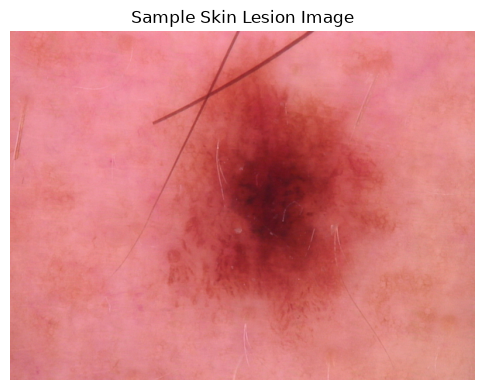

In [13]:
plt.figure(figsize=(6, 5))

plt.imshow(img)
plt.axis("off")
plt.title("Sample Skin Lesion Image")

plt.show()

convert image into numpy array

In [14]:
import numpy as np
img_array = np.array(img)

print("Shape:", img_array.shape)
print("Data type:", img_array.dtype)
print("Minimum:", img_array.min())
print("Maximum:", img_array.max())

Shape: (450, 600, 3)
Data type: uint8
Minimum: 14
Maximum: 255


In [15]:
img_resized = img.resize((224, 224))

print(img_resized.size)

(224, 224)


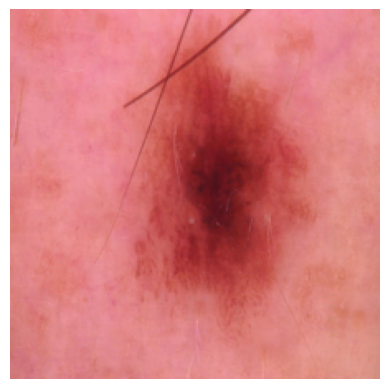

In [16]:
plt.imshow(img_resized)
plt.axis("off")
plt.show()

In [18]:
#Dataset preparation

from sklearn.model_selection import train_test_split

data = df.copy()

data["image_path"] = data["image_id"].apply(
    lambda x: next(
        (p for p in image_files if os.path.basename(p).split(".")[0] == x),
        None
    )
)

data = data.dropna(subset=["image_path"])

print("Images matched:", len(data))
print(data[["image_id", "dx", "image_path"]].head())

  Using cached scikit_learn-1.9.1-cp311-cp311-win_amd64.whl.metadata (9.3 kB)
  Using cached scipy-1.17.1-cp311-cp311-win_amd64.whl.metadata (60 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached narwhals-2.26.0-py3-none-any.whl.metadata (15 kB)
  Using cached threadpoolctl-3.7.0-py3-none-any.whl.metadata (24 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
Using cached scikit_learn-1.9.1-cp311-cp311-win_amd64.whl (8.3 MB)
Using cached joblib-1.6.0-py3-none-any.whl (306 kB)
Using cached narwhals-2.26.0-py3-none-any.whl (474 kB)
Using cached scipy-1.17.1-cp311-cp311-win_amd64.whl (36.6 MB)
Using cached threadpoolctl-3.7.0-py3-none-any.whl (26 kB)
Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Images matched: 10015
       image_id   dx                                         image_path
0  ISIC_0027419  bkl  ../data/raw/HAM10000_images_part_1\ISIC_002741...
1  ISIC_0025030  bkl  ../data/raw/HAM10000_images_part_1\ISIC_002503...
2  ISIC_0026769  bkl  ../data/raw/HAM10000_images_part_1\ISIC_002676...
3  ISIC_0025661  bkl  ../data/raw/HAM10000_images_part_1\ISIC_002566...
4  ISIC_0031633  bkl  ../data/raw/HAM10000_images_part_2\ISIC_003163...


In [19]:
train_df, temp_df = train_test_split(
    data,
    test_size=0.20,
    stratify=data["dx"],
    random_state=42
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["dx"],
    random_state=42
)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

Train: 8012
Validation: 1001
Test: 1002


Add label Encode
    CNN does not use string directly. we convert labels into numeric form

In [22]:
from sklearn.preprocessing import LabelEncoder
import tensorflow as tf
import numpy as np

label_encoder = LabelEncoder()

train_df = train_df.copy()
val_df = val_df.copy()
test_df = test_df.copy()

train_df["label"] = label_encoder.fit_transform(train_df["dx"])
val_df["label"] = label_encoder.transform(val_df["dx"])
test_df["label"] = label_encoder.transform(test_df["dx"])

class_names = list(label_encoder.classes_)

print("Classes:", class_names)
print("Number of classes:", len(class_names))

Classes: ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']
Number of classes: 7


Image procesing

In [23]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

def load_and_preprocess(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32)

    image = tf.keras.applications.mobilenet_v2.preprocess_input(image)

    return image, label

Tensorflow dataset

In [24]:
train_ds = tf.data.Dataset.from_tensor_slices(
    (train_df["image_path"].values, train_df["label"].values)
)

val_ds = tf.data.Dataset.from_tensor_slices(
    (val_df["image_path"].values, val_df["label"].values)
)

test_ds = tf.data.Dataset.from_tensor_slices(
    (test_df["image_path"].values, test_df["label"].values)
)

Apply processing

In [25]:
train_ds = (
    train_ds
    .shuffle(len(train_df), seed=42)
    .map(load_and_preprocess, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

val_ds = (
    val_ds
    .map(load_and_preprocess, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

test_ds = (
    test_ds
    .map(load_and_preprocess, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

verify pipline

In [26]:
images, labels = next(iter(train_ds))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Image dtype:", images.dtype)
print("Label dtype:", labels.dtype)

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Image dtype: <dtype: 'float32'>
Label dtype: <dtype: 'int64'>


Now prepare MobileNetV2 model

In [27]:
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2

num_classes = len(class_names)

base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.2),
    layers.Dense(num_classes, activation="softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 7)              │         8,967 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,266,951 (8.65 MB)

 Trainable params: 8,967 (35.03 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Compile

In [29]:
model.compile (
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss = "sparse_categorical_crossentropy",
    metrics = ["accuracy"]
)

Training

In [30]:
EPOCHS = 5

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)
print("Model trained successfully.")

Epoch 1/5


d:\ML intern prj\SkinAI\venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


251/251 ━━━━━━━━━━━━━━━━━━━━ 294s 1s/step - accuracy: 0.6192 - loss: 1.2405 - val_accuracy: 0.6743 - val_loss: 0.9907
Epoch 2/5
251/251 ━━━━━━━━━━━━━━━━━━━━ 277s 1s/step - accuracy: 0.6665 - loss: 0.9956 - val_accuracy: 0.6953 - val_loss: 0.8857
Epoch 3/5
251/251 ━━━━━━━━━━━━━━━━━━━━ 240s 956ms/step - accuracy: 0.6872 - loss: 0.9096 - val_accuracy: 0.7063 - val_loss: 0.8310
Epoch 4/5
251/251 ━━━━━━━━━━━━━━━━━━━━ 261s 1s/step - accuracy: 0.7009 - loss: 0.8604 - val_accuracy: 0.7093 - val_loss: 0.7906
Epoch 5/5
251/251 ━━━━━━━━━━━━━━━━━━━━ 302s 1s/step - accuracy: 0.7064 - loss: 0.8226 - val_accuracy: 0.7203 - val_loss: 0.7698
Model trained successfully.


Training graph

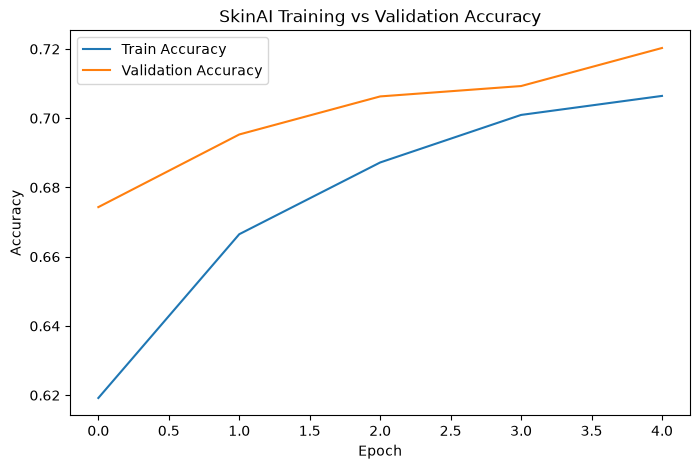

In [31]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("SkinAI Training vs Validation Accuracy")
plt.legend()

plt.show()

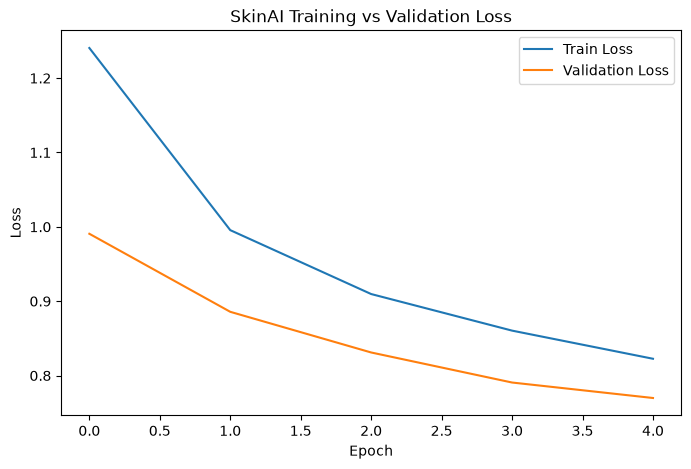

In [32]:
#loss graph
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("SkinAI Training vs Validation Loss")
plt.legend()

plt.show()

Test set Evaluation

In [33]:
test_loss, test_accuracy = model.evaluate(test_ds)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

32/32 ━━━━━━━━━━━━━━━━━━━━ 31s 960ms/step - accuracy: 0.7176 - loss: 0.7772
Test Loss: 0.7771822810173035
Test Accuracy: 0.7175648808479309


Generate prediction

In [34]:
y_true = []
y_pred = []

for images, labels in test_ds:
    predictions = model.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("True labels:", y_true.shape)
print("Predicted labels:", y_pred.shape)

True labels: (1002,)
Predicted labels: (1002,)


Classification Report

In [35]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names,
        digits=4
    )
)

              precision    recall  f1-score   support

       akiec     0.4348    0.3125    0.3636        32
         bcc     0.4000    0.1923    0.2597        52
         bkl     0.4304    0.3091    0.3598       110
          df     0.0000    0.0000    0.0000        11
         mel     0.4310    0.2232    0.2941       112
          nv     0.7840    0.9523    0.8600       671
        vasc     0.5000    0.0714    0.1250        14

    accuracy                         0.7176      1002
   macro avg     0.4257    0.2944    0.3232      1002
weighted avg     0.6621    0.7176    0.6751      1002



d:\ML intern prj\SkinAI\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\ML intern prj\SkinAI\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\ML intern prj\SkinAI\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


Confusion matrix

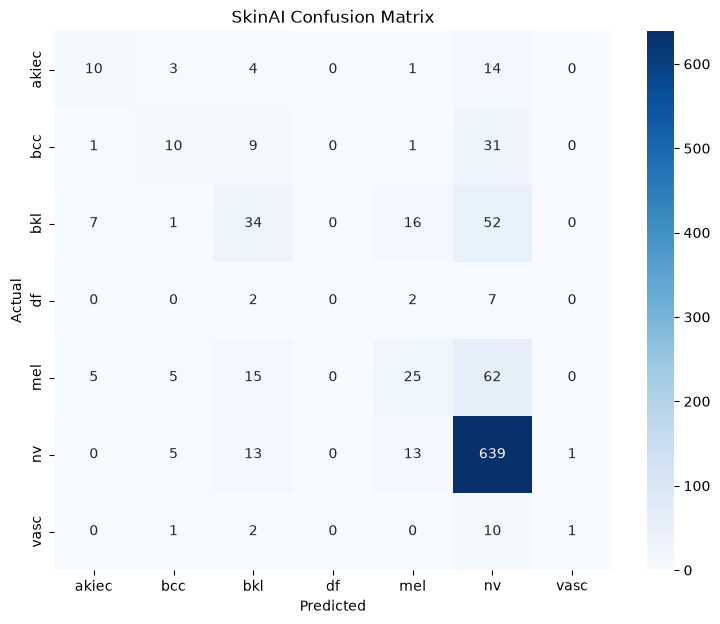

In [36]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("SkinAI Confusion Matrix")

plt.show()

Save model

In [37]:
model.save("../models/skinai_mobilenetv2_baseline.keras")

In [38]:
import os

print(
    "Model exists:",
    os.path.exists("../models/skinai_mobilenetv2_baseline.keras")
)


Model exists: True


In [39]:
#check training history
print("Final Training Accuracy:", history.history["accuracy"][-1])
print("Final Validation Accuracy:", history.history["val_accuracy"][-1])

print("Final Training Loss:", history.history["loss"][-1])
print("Final Validation Loss:", history.history["val_loss"][-1])


Final Training Accuracy: 0.7064403295516968
Final Validation Accuracy: 0.7202796936035156
Final Training Loss: 0.8225961923599243
Final Validation Loss: 0.7698280811309814


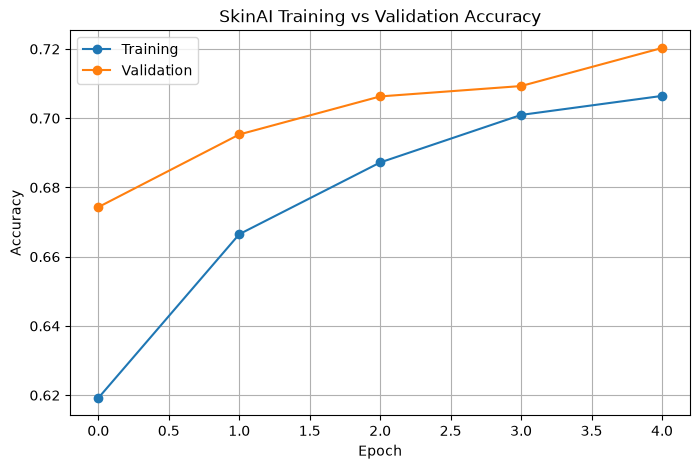

In [40]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], marker="o", label="Training")
plt.plot(history.history["val_accuracy"], marker="o", label="Validation")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("SkinAI Training vs Validation Accuracy")
plt.legend()
plt.grid(True)

plt.show()

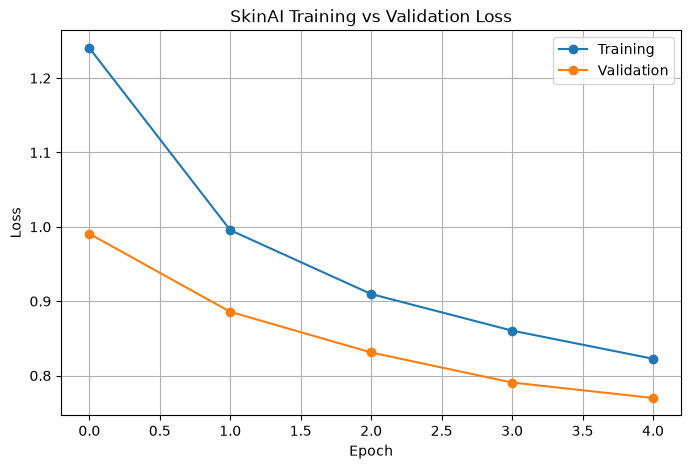

In [41]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], marker="o", label="Training")
plt.plot(history.history["val_loss"], marker="o", label="Validation")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("SkinAI Training vs Validation Loss")
plt.legend()
plt.grid(True)

plt.show()

In [42]:
train_acc = history.history["accuracy"]
val_acc = history.history["val_accuracy"]

for epoch, (train, val) in enumerate(zip(train_acc, val_acc), 1):
    print(
        f"Epoch {epoch}: "
        f"Train={train:.4f}, "
        f"Validation={val:.4f}, "
        f"Gap={train-val:.4f}"
    )

Epoch 1: Train=0.6192, Validation=0.6743, Gap=-0.0551
Epoch 2: Train=0.6665, Validation=0.6953, Gap=-0.0288
Epoch 3: Train=0.6872, Validation=0.7063, Gap=-0.0191
Epoch 4: Train=0.7009, Validation=0.7093, Gap=-0.0083
Epoch 5: Train=0.7064, Validation=0.7203, Gap=-0.0138


Model improvement

unfreeze MobileNetV2 Layers

In [43]:
base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

print("Trainable layers:", sum(layer.trainable for layer in base_model.layers))

Trainable layers: 30


In [45]:
#Take very small learning rate for fine tunning
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

Fine tune

In [46]:
fine_tune_epochs = 5

history_fine = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=fine_tune_epochs
)

Epoch 1/5


d:\ML intern prj\SkinAI\venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


251/251 ━━━━━━━━━━━━━━━━━━━━ 357s 1s/step - accuracy: 0.6862 - loss: 0.8906 - val_accuracy: 0.7253 - val_loss: 0.7999
Epoch 2/5
251/251 ━━━━━━━━━━━━━━━━━━━━ 371s 1s/step - accuracy: 0.7455 - loss: 0.7288 - val_accuracy: 0.7243 - val_loss: 0.8003
Epoch 3/5
251/251 ━━━━━━━━━━━━━━━━━━━━ 408s 2s/step - accuracy: 0.7691 - loss: 0.6587 - val_accuracy: 0.7293 - val_loss: 0.7504
Epoch 4/5
251/251 ━━━━━━━━━━━━━━━━━━━━ 393s 2s/step - accuracy: 0.7927 - loss: 0.5971 - val_accuracy: 0.7363 - val_loss: 0.7160
Epoch 5/5
251/251 ━━━━━━━━━━━━━━━━━━━━ 395s 2s/step - accuracy: 0.8099 - loss: 0.5470 - val_accuracy: 0.7542 - val_loss: 0.6817


In [48]:
print(
    "Final Fine-tuning Training Accuracy:",
    history_fine.history["accuracy"][-1]
)

print(
    "Final Fine-tuning Validation Accuracy:",
    history_fine.history["val_accuracy"][-1]
)

Final Fine-tuning Training Accuracy: 0.8099101185798645
Final Fine-tuning Validation Accuracy: 0.7542457580566406


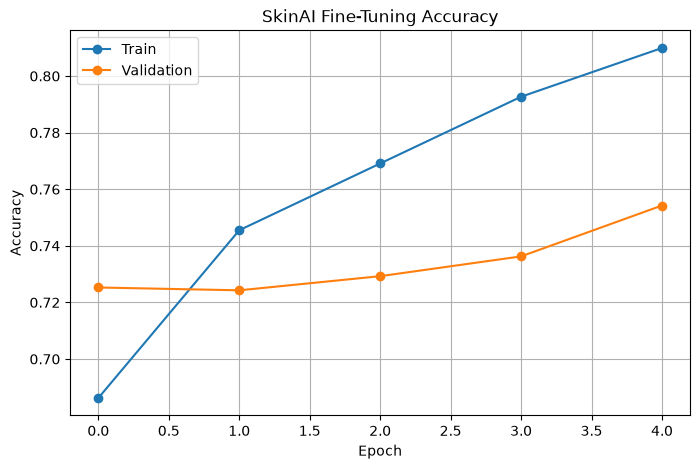

In [49]:
#final tuning curves
plt.figure(figsize=(8, 5))

plt.plot(
    history_fine.history["accuracy"],
    marker="o",
    label="Train"
)

plt.plot(
    history_fine.history["val_accuracy"],
    marker="o",
    label="Validation"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("SkinAI Fine-Tuning Accuracy")
plt.legend()
plt.grid(True)

plt.show()

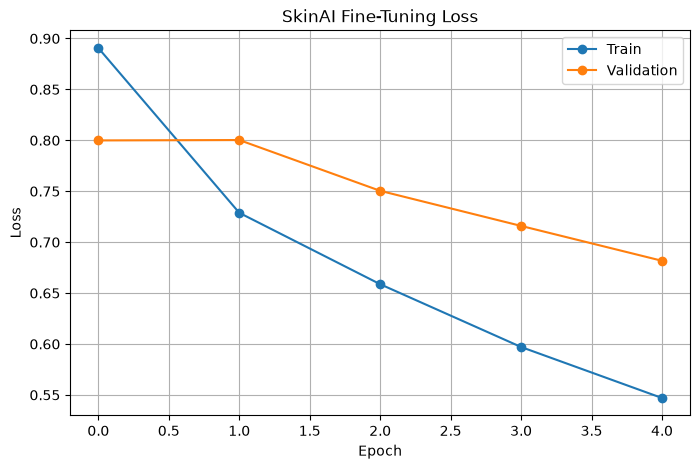

In [50]:
# loss graph
plt.figure(figsize=(8, 5))

plt.plot(
    history_fine.history["loss"],
    marker="o",
    label="Train"
)

plt.plot(
    history_fine.history["val_loss"],
    marker="o",
    label="Validation"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("SkinAI Fine-Tuning Loss")
plt.legend()
plt.grid(True)

plt.show()

In [51]:
#Test Set Evaluation 
test_loss, test_accuracy = model.evaluate(test_ds)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

32/32 ━━━━━━━━━━━━━━━━━━━━ 29s 884ms/step - accuracy: 0.7685 - loss: 0.7056
Test Loss: 0.7056368589401245
Test Accuracy: 0.7684630751609802


In [52]:
from sklearn.metrics import classification_report
import numpy as np

y_true = []
y_pred = []

for images, labels in test_ds:
    predictions = model.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names,
        digits=4
    )
)

              precision    recall  f1-score   support

       akiec     0.4545    0.3125    0.3704        32
         bcc     0.5088    0.5577    0.5321        52
         bkl     0.6909    0.3455    0.4606       110
          df     0.0000    0.0000    0.0000        11
         mel     0.5500    0.2946    0.3837       112
          nv     0.8177    0.9762    0.8899       671
        vasc     0.7143    0.3571    0.4762        14

    accuracy                         0.7685      1002
   macro avg     0.5337    0.4062    0.4447      1002
weighted avg     0.7358    0.7685    0.7355      1002



d:\ML intern prj\SkinAI\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\ML intern prj\SkinAI\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\ML intern prj\SkinAI\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [53]:
model.save("../models/skinai_mobilenetv2_finetuned.keras")


In [54]:
print(train_df["dx"].value_counts())

dx
nv       5364
mel       890
bkl       879
bcc       411
akiec     262
vasc      114
df         92
Name: count, dtype: int64


In [55]:
#weights check
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = np.unique(train_df["label"])

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_df["label"]
)

class_weights = dict(zip(classes, weights))

print("Class Weights:")
for class_id, weight in class_weights.items():
    print(class_names[class_id], ":", round(weight, 4))

Class Weights:
akiec : 4.3686
bcc : 2.7848
bkl : 1.3021
df : 12.441
mel : 1.286
nv : 0.2134
vasc : 10.0401


In [56]:
#class-weighted fine-tunning
class_weight_history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    class_weight=class_weights
)


Epoch 1/5


d:\ML intern prj\SkinAI\venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


251/251 ━━━━━━━━━━━━━━━━━━━━ 351s 1s/step - accuracy: 0.7755 - loss: 0.8771 - val_accuracy: 0.7672 - val_loss: 0.6282
Epoch 2/5
251/251 ━━━━━━━━━━━━━━━━━━━━ 378s 2s/step - accuracy: 0.7667 - loss: 0.6523 - val_accuracy: 0.7832 - val_loss: 0.5910
Epoch 3/5
251/251 ━━━━━━━━━━━━━━━━━━━━ 334s 1s/step - accuracy: 0.7793 - loss: 0.5719 - val_accuracy: 0.7872 - val_loss: 0.5878
Epoch 4/5
251/251 ━━━━━━━━━━━━━━━━━━━━ 337s 1s/step - accuracy: 0.7868 - loss: 0.5161 - val_accuracy: 0.7772 - val_loss: 0.6137
Epoch 5/5
251/251 ━━━━━━━━━━━━━━━━━━━━ 331s 1s/step - accuracy: 0.8078 - loss: 0.4522 - val_accuracy: 0.7782 - val_loss: 0.6270


In [57]:
print(
    "Final Class-Weighted Training Accuracy:",
    class_weight_history.history["accuracy"][-1]
)

print(
    "Final Class-Weighted Validation Accuracy:",
    class_weight_history.history["val_accuracy"][-1]
)

Final Class-Weighted Training Accuracy: 0.8077883124351501
Final Class-Weighted Validation Accuracy: 0.7782217860221863


In [58]:
model.save("../models/skinai_class_weighted.keras")

In [59]:
y_true_weighted = []
y_pred_weighted = []

for images, labels in test_ds:
    predictions = model.predict(images, verbose=0)

    y_true_weighted.extend(labels.numpy())
    y_pred_weighted.extend(np.argmax(predictions, axis=1))

y_true_weighted = np.array(y_true_weighted)
y_pred_weighted = np.array(y_pred_weighted)

In [60]:
#classification report
from sklearn.metrics import classification_report

print(
    classification_report(
        y_true_weighted,
        y_pred_weighted,
        target_names=class_names,
        digits=4
    )
)

              precision    recall  f1-score   support

       akiec     0.4130    0.5938    0.4872        32
         bcc     0.4507    0.6154    0.5203        52
         bkl     0.5800    0.5273    0.5524       110
          df     0.4286    0.5455    0.4800        11
         mel     0.4602    0.4643    0.4622       112
          nv     0.9250    0.8823    0.9031       671
        vasc     0.5556    0.7143    0.6250        14

    accuracy                         0.7675      1002
   macro avg     0.5447    0.6204    0.5757      1002
weighted avg     0.7836    0.7675    0.7737      1002



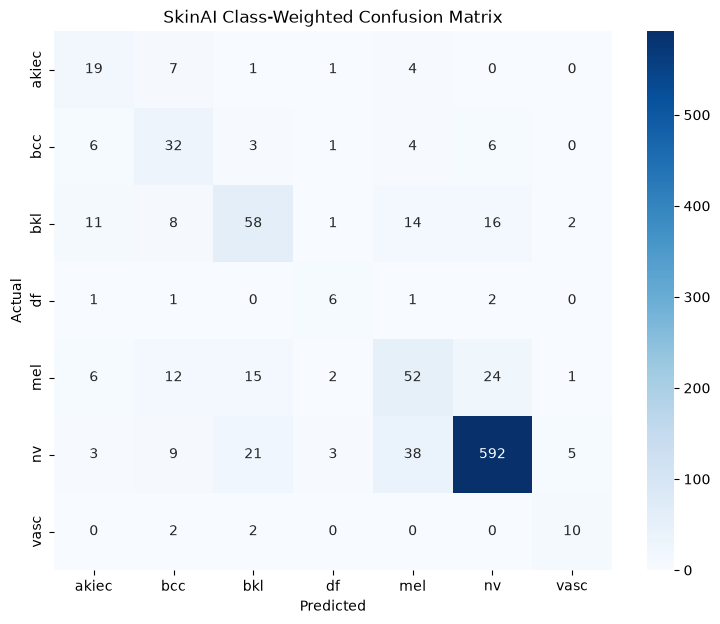

In [61]:
#confusion matrix
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(
    y_true_weighted,
    y_pred_weighted
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("SkinAI Class-Weighted Confusion Matrix")
plt.show()

In [62]:
print("Class order:")
print(class_names)

print("\nConfusion Matrix:")
print(cm)

Class order:
['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']

Confusion Matrix:
[[ 19   7   1   1   4   0   0]
 [  6  32   3   1   4   6   0]
 [ 11   8  58   1  14  16   2]
 [  1   1   0   6   1   2   0]
 [  6  12  15   2  52  24   1]
 [  3   9  21   3  38 592   5]
 [  0   2   2   0   0   0  10]]


In [63]:
model.save("../models/skinai_class_weighted_final.keras")

import callbacks

In [64]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

In [65]:
#call backs
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True,
    verbose=1
)

checkpoint = ModelCheckpoint(
    "../models/skinai_best.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

In [66]:
#class weighted training
history_best = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    class_weight=class_weights,
    callbacks=[
        early_stopping,
        checkpoint
    ]
)

Epoch 1/10


d:\ML intern prj\SkinAI\venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


251/251 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8225 - loss: 0.4138
Epoch 1: val_loss improved from None to 0.66566, saving model to ../models/skinai_best.keras

Epoch 1: finished saving model to ../models/skinai_best.keras
251/251 ━━━━━━━━━━━━━━━━━━━━ 401s 2s/step - accuracy: 0.8225 - loss: 0.4138 - val_accuracy: 0.7682 - val_loss: 0.6657
Epoch 2/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8249 - loss: 0.3835
Epoch 2: val_loss did not improve from 0.66566
251/251 ━━━━━━━━━━━━━━━━━━━━ 387s 2s/step - accuracy: 0.8249 - loss: 0.3835 - val_accuracy: 0.7652 - val_loss: 0.6705
Epoch 3/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.8387 - loss: 0.3459
Epoch 3: val_loss did not improve from 0.66566
251/251 ━━━━━━━━━━━━━━━━━━━━ 407s 2s/step - accuracy: 0.8387 - loss: 0.3459 - val_accuracy: 0.7672 - val_loss: 0.6787
Epoch 3: early stopping
Restoring model weights from the end of the best epoch: 1.


In [67]:
print(
    "Best Training Accuracy:",
    max(history_best.history["accuracy"])
)

print(
    "Best Validation Accuracy:",
    max(history_best.history["val_accuracy"])
)

print(
    "Best Validation Loss:",
    min(history_best.history["val_loss"])
)

Best Training Accuracy: 0.8387418985366821
Best Validation Accuracy: 0.7682317495346069
Best Validation Loss: 0.6656584143638611


In [68]:
test_loss_best, test_accuracy_best = model.evaluate(test_ds)

print("Best Model Test Loss:", test_loss_best)
print("Best Model Test Accuracy:", test_accuracy_best)

32/32 ━━━━━━━━━━━━━━━━━━━━ 32s 961ms/step - accuracy: 0.7535 - loss: 0.6782
Best Model Test Loss: 0.6782141327857971
Best Model Test Accuracy: 0.7534930109977722


In [69]:
test_loss_best, test_accuracy_best = model.evaluate(test_ds)

print("Best Model Test Loss:", test_loss_best)
print("Best Model Test Accuracy:", test_accuracy_best)

32/32 ━━━━━━━━━━━━━━━━━━━━ 33s 1s/step - accuracy: 0.7535 - loss: 0.6782
Best Model Test Loss: 0.6782141327857971
Best Model Test Accuracy: 0.7534930109977722


identify convolutional layer

In [70]:
import tensorflow as tf

base_model = model.layers[0]

last_conv_layer = None

for layer in reversed(base_model.layers):
    if isinstance(layer, tf.keras.layers.Conv2D):
        last_conv_layer = layer
        break

print("Last Conv2D layer:", last_conv_layer.name)
print("Output shape:", last_conv_layer.output.shape)

Last Conv2D layer: Conv_1
Output shape: (None, 7, 7, 1280)


Grad-CAM function

In [71]:
import tensorflow as tf
import numpy as np

def make_gradcam_heatmap(image, model, last_conv_layer, pred_index=None):
    grad_model = tf.keras.models.Model(
        inputs=model.inputs,
        outputs=[
            last_conv_layer.output,
            model.output
        ]
    )

    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(image)

        if pred_index is None:
            pred_index = tf.argmax(predictions[0])

        class_score = predictions[:, pred_index]

    gradients = tape.gradient(
        class_score,
        conv_outputs
    )

    pooled_gradients = tf.reduce_mean(
        gradients,
        axis=(0, 1, 2)
    )

    conv_outputs = conv_outputs[0]

    heatmap = conv_outputs @ pooled_gradients[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    heatmap = tf.maximum(heatmap, 0)
    heatmap /= tf.maximum(
        tf.reduce_max(heatmap),
        tf.keras.backend.epsilon()
    )

    return heatmap.numpy()

In [75]:
import matplotlib.pyplot as plt
import numpy as np

sample_path = test_df.iloc[0]["image_path"]
true_label = test_df.iloc[0]["label"]

print("Image:", sample_path)
print("Actual Class:", class_names[true_label])

Image: ../data/raw/HAM10000_images_part_1\ISIC_0026911.jpg
Actual Class: nv


In [76]:
image = tf.io.read_file(sample_path)
image = tf.image.decode_jpeg(image, channels=3)
image = tf.image.resize(image, IMG_SIZE)
image = tf.cast(image, tf.float32)

processed_image = tf.keras.applications.mobilenet_v2.preprocess_input(
    image
)

input_image = tf.expand_dims(processed_image, axis=0)

print("Input shape:", input_image.shape)

Input shape: (1, 224, 224, 3)


In [77]:
prediction = model.predict(input_image, verbose=0)

predicted_index = np.argmax(prediction[0])
predicted_class = class_names[predicted_index]
confidence = prediction[0][predicted_index]

print("Actual Class:", class_names[true_label])
print("Predicted Class:", predicted_class)
print("Confidence:", round(float(confidence) * 100, 2), "%")

Actual Class: nv
Predicted Class: nv
Confidence: 88.54 %


In [79]:
_ = model(input_image)

print("Model output shape:", model(input_image).shape)

Model output shape: (1, 7)


In [84]:
def make_gradcam_heatmap(image, model, base_model, last_conv_layer, pred_index=None):

    grad_model = tf.keras.models.Model(
        inputs=base_model.input,
        outputs=[
            last_conv_layer.output,
            base_model.output
        ]
    )

    with tf.GradientTape() as tape:

        conv_outputs, base_output = grad_model(
            image,
            training=False
        )

        x = model.layers[1](base_output)
        x = model.layers[2](x, training=False)
        predictions = model.layers[3](x)

        if pred_index is None:
            pred_index = tf.argmax(predictions[0])

        class_score = predictions[:, pred_index]

    gradients = tape.gradient(
        class_score,
        conv_outputs
    )

    pooled_gradients = tf.reduce_mean(
        gradients,
        axis=(0, 1, 2)
    )

    conv_outputs = conv_outputs[0]

    heatmap = conv_outputs @ pooled_gradients[..., tf.newaxis]

    heatmap = tf.squeeze(heatmap)

    heatmap = tf.maximum(heatmap, 0)

    heatmap = heatmap / (
        tf.reduce_max(heatmap) +
        tf.keras.backend.epsilon()
    )

    return heatmap.numpy()

In [85]:
heatmap = make_gradcam_heatmap(
    input_image,
    model,
    base_model,
    last_conv_layer,
    pred_index=predicted_index
)

print("Heatmap shape:", heatmap.shape)
print("Heatmap range:", heatmap.min(), "to", heatmap.max())

Heatmap shape: (7, 7)
Heatmap range: 0.0 to 0.99999213


In [ ]:
#load original image
import cv2
import numpy as np
import matplotlib.pyplot as plt

original_image = cv2.imread(sample_path)
original_image = cv2.cvtColor(original_image, cv2.COLOR_BGR2RGB)

original_image = cv2.resize(
    original_image,
    IMG_SIZE
)

print("Image shape:", original_image.shape)

   ---------------------------------------- 0.0/43.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/43.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/43.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/43.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/43.8 MB 262.6 kB/s eta 0:02:47
   ---------------------------------------- 0.1/43.8 MB 365.7 kB/s eta 0:02:00
   ---------------------------------------- 0.1/43.8 MB 438.1 kB/s eta 0:01:40
   ---------------------------------------- 0.1/43.8 MB 481.4 kB/s eta 0:01:31
   ---------------------------------------- 0.2/43.8 MB 724.0 kB/s eta 0:01:01
   ---------------------------------------- 0.3/43.8 MB 714.4 kB/s eta 0:01:01
   ---------------------------------------- 0.4/43.8 MB 1.1 MB/s eta 0:00:42
   ---------------------------------------- 0.5/43.8 MB 1.2 MB/s eta 0:00:36
    --------------------------------------- 0.8/43.8 MB 1.6 MB/s eta 0:00:28
    -----------


[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Image shape: (224, 224, 3)


In [89]:
heatmap_resized = cv2.resize(
    heatmap,
    (224, 224)
)

heatmap_uint8 = np.uint8(
    255 * heatmap_resized
)

heatmap_color = cv2.applyColorMap(
    heatmap_uint8,
    cv2.COLORMAP_JET
)

heatmap_color = cv2.cvtColor(
    heatmap_color,
    cv2.COLOR_BGR2RGB
)

In [90]:
overlay = cv2.addWeighted(
    original_image,
    0.6,
    heatmap_color,
    0.4,
    0
)

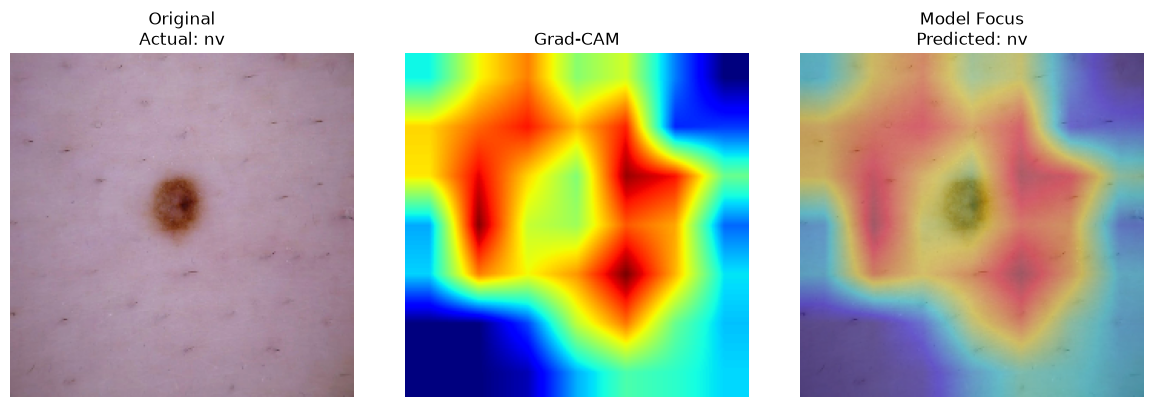

In [91]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(original_image)
plt.title(
    f"Original\nActual: {class_names[true_label]}"
)
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(heatmap_resized, cmap="jet")
plt.title("Grad-CAM")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(overlay)
plt.title(
    f"Model Focus\nPredicted: {predicted_class}"
)
plt.axis("off")

plt.tight_layout()
plt.show()

In [92]:
#select test images 
sample_indices = [0, 1, 2, 3, 4, 5]

samples = test_df.iloc[sample_indices]

print("Selected images:", len(samples))

Selected images: 6


In [93]:
#GRAD-CAM visualization
def visualize_gradcam(sample_path):

    image = tf.io.read_file(sample_path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32)

    processed = tf.keras.applications.mobilenet_v2.preprocess_input(image)
    input_img = tf.expand_dims(processed, axis=0)

    prediction = model.predict(input_img, verbose=0)

    predicted_index = np.argmax(prediction[0])
    predicted_class = class_names[predicted_index]
    confidence = prediction[0][predicted_index]

    heatmap = make_gradcam_heatmap(
        input_img,
        model,
        base_model,
        last_conv_layer,
        pred_index=predicted_index
    )

    original = image.numpy().astype("uint8")

    heatmap_resized = cv2.resize(
        heatmap,
        (IMG_SIZE[1], IMG_SIZE[0])
    )

    heatmap_uint8 = np.uint8(255 * heatmap_resized)

    heatmap_color = cv2.applyColorMap(
        heatmap_uint8,
        cv2.COLORMAP_JET
    )

    heatmap_color = cv2.cvtColor(
        heatmap_color,
        cv2.COLOR_BGR2RGB
    )

    overlay = cv2.addWeighted(
        original,
        0.6,
        heatmap_color,
        0.4,
        0
    )

    return original, overlay, predicted_class, confidence

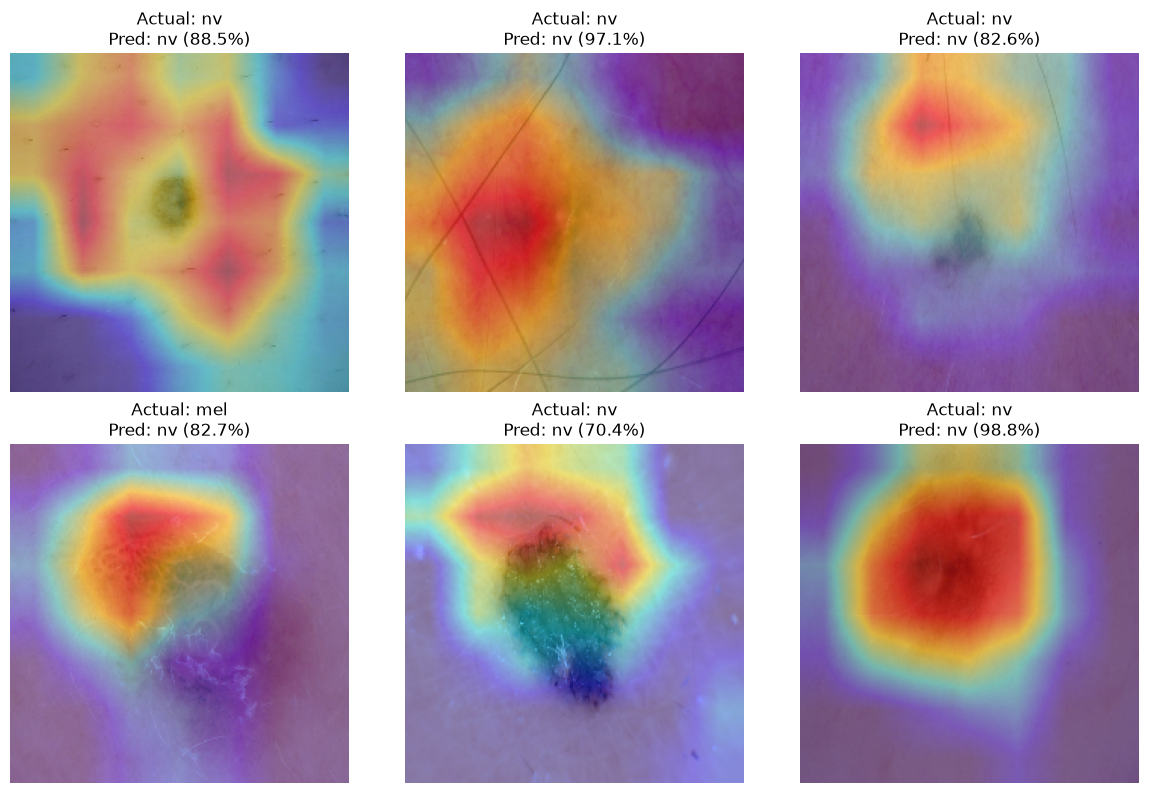

In [94]:
#display images
fig, axes = plt.subplots(
    2,
    3,
    figsize=(12, 8)
)

for ax, (_, row) in zip(
    axes.flat,
    samples.iterrows()
):

    original, overlay, predicted_class, confidence = visualize_gradcam(
        row["image_path"]
    )

    ax.imshow(overlay)

    actual_class = row["dx"]

    ax.set_title(
        f"Actual: {actual_class}\n"
        f"Pred: {predicted_class} "
        f"({confidence * 100:.1f}%)"
    )

    ax.axis("off")

plt.tight_layout()
plt.show()

In [95]:
#calculate test prediction
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np

y_true = []
y_pred = []
y_confidence = []

for images, labels in test_ds:

    predictions = model.predict(images, verbose=0)

    predicted_labels = np.argmax(predictions, axis=1)
    confidence = np.max(predictions, axis=1)

    y_true.extend(labels.numpy())
    y_pred.extend(predicted_labels)
    y_confidence.extend(confidence)

y_true = np.array(y_true)
y_pred = np.array(y_pred)
y_confidence = np.array(y_confidence)

print("Total test samples:", len(y_true))
print("Correct predictions:", np.sum(y_true == y_pred))
print("Incorrect predictions:", np.sum(y_true != y_pred))

Total test samples: 1002
Correct predictions: 755
Incorrect predictions: 247


In [96]:
#correct vs incorrect confidence
correct_mask = y_true == y_pred
incorrect_mask = y_true != y_pred

correct_confidence = y_confidence[correct_mask]
incorrect_confidence = y_confidence[incorrect_mask]

print(
    "Average confidence - Correct:",
    round(correct_confidence.mean() * 100, 2),
    "%"
)

print(
    "Average confidence - Incorrect:",
    round(incorrect_confidence.mean() * 100, 2),
    "%"
)

Average confidence - Correct: 82.29 %
Average confidence - Incorrect: 57.57 %


In [97]:
#per class accuracy
cm = confusion_matrix(
    y_true,
    y_pred
)

class_accuracy = cm.diagonal() / cm.sum(axis=1)

for class_name, accuracy in zip(
    class_names,
    class_accuracy
):
    print(
        f"{class_name}: {accuracy * 100:.2f}%"
    )

akiec: 59.38%
bcc: 67.31%
bkl: 52.73%
df: 54.55%
mel: 46.43%
nv: 85.69%
vasc: 71.43%


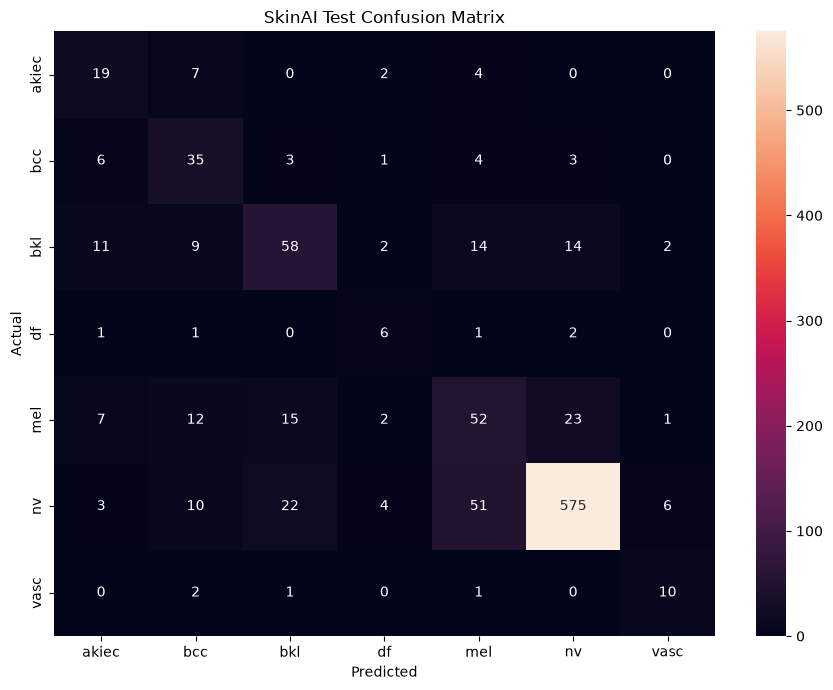

In [98]:
#confusion matrix
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("SkinAI Test Confusion Matrix")

plt.tight_layout()
plt.show()

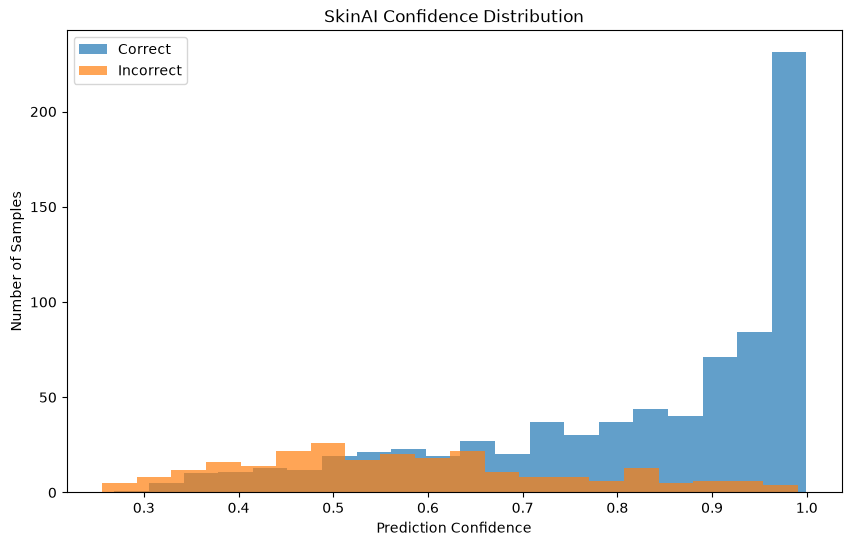

In [99]:
#confidence distribution
plt.figure(figsize=(10, 6))

plt.hist(
    correct_confidence,
    bins=20,
    alpha=0.7,
    label="Correct"
)

plt.hist(
    incorrect_confidence,
    bins=20,
    alpha=0.7,
    label="Incorrect"
)

plt.xlabel("Prediction Confidence")
plt.ylabel("Number of Samples")
plt.title("SkinAI Confidence Distribution")

plt.legend()
plt.show()

In [100]:
#Threshold analysis
thresholds = [0.50, 0.60, 0.70, 0.80, 0.90]

for threshold in thresholds:

    accepted = y_confidence >= threshold

    if np.sum(accepted) == 0:
        continue

    accepted_accuracy = np.mean(
        y_true[accepted] == y_pred[accepted]
    )

    coverage = np.mean(accepted)

    print(
        f"Threshold: {threshold:.0%} | "
        f"Accuracy: {accepted_accuracy:.2%} | "
        f"Coverage: {coverage:.2%}"
    )

Threshold: 50% | Accuracy: 82.00% | Coverage: 84.83%
Threshold: 60% | Accuracy: 86.57% | Coverage: 73.55%
Threshold: 70% | Accuracy: 91.31% | Coverage: 63.17%
Threshold: 80% | Accuracy: 93.33% | Coverage: 52.40%
Threshold: 90% | Accuracy: 96.56% | Coverage: 37.72%


In [101]:
#collect validations predictions
val_true = []
val_pred = []
val_confidence = []

for images, labels in val_ds:

    predictions = model.predict(images, verbose=0)

    predicted_labels = np.argmax(predictions, axis=1)
    confidence = np.max(predictions, axis=1)

    val_true.extend(labels.numpy())
    val_pred.extend(predicted_labels)
    val_confidence.extend(confidence)

val_true = np.array(val_true)
val_pred = np.array(val_pred)
val_confidence = np.array(val_confidence)

print("Validation samples:", len(val_true))

Validation samples: 1001


In [102]:
#test validation threshold
thresholds = [0.50, 0.60, 0.70, 0.80, 0.90]

for threshold in thresholds:

    accepted = val_confidence >= threshold

    if np.sum(accepted) == 0:
        continue

    accepted_accuracy = np.mean(
        val_true[accepted] == val_pred[accepted]
    )

    coverage = np.mean(accepted)

    print(
        f"Threshold: {threshold:.0%} | "
        f"Accuracy: {accepted_accuracy:.2%} | "
        f"Coverage: {coverage:.2%}"
    )

Threshold: 50% | Accuracy: 82.58% | Coverage: 86.01%
Threshold: 60% | Accuracy: 87.79% | Coverage: 72.83%
Threshold: 70% | Accuracy: 91.56% | Coverage: 62.74%
Threshold: 80% | Accuracy: 94.84% | Coverage: 52.25%
Threshold: 90% | Accuracy: 97.41% | Coverage: 34.77%


In [103]:
#final test evaluation
FINAL_THRESHOLD = 0.80

accepted = y_confidence >= FINAL_THRESHOLD

accepted_true = y_true[accepted]
accepted_pred = y_pred[accepted]

final_accuracy = np.mean(
    accepted_true == accepted_pred
)

coverage = np.mean(accepted)

print("Final Threshold:", FINAL_THRESHOLD)
print(
    "Accepted Test Accuracy:",
    round(final_accuracy * 100, 2),
    "%"
)
print(
    "Test Coverage:",
    round(coverage * 100, 2),
    "%"
)
print(
    "Rejected / Uncertain:",
    round((1 - coverage) * 100, 2),
    "%"
)

Final Threshold: 0.8
Accepted Test Accuracy: 93.33 %
Test Coverage: 52.4 %
Rejected / Uncertain: 47.6 %


In [104]:
print(model.name)
print(model.input_shape)
print(model.output_shape)

sequential
(None, 224, 224, 3)
(None, 7)


In [105]:
model.save(
    "../models/skinai_final.keras"
)

print("SkinAI final model saved successfully.")

SkinAI final model saved successfully.


In [106]:
import json

with open("../models/class_names.json", "w") as f:
    json.dump(class_names, f)

print("Class names saved:", class_names)

Class names saved: ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']
